In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

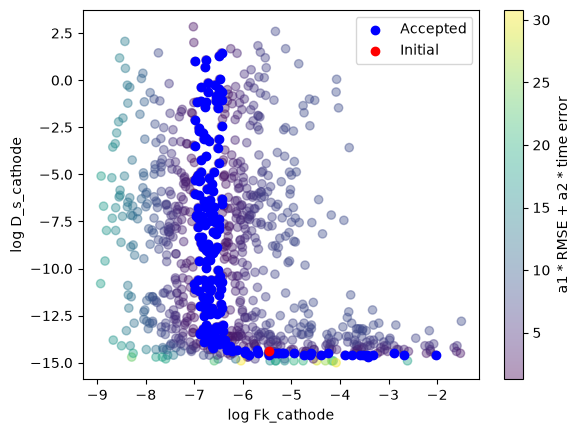

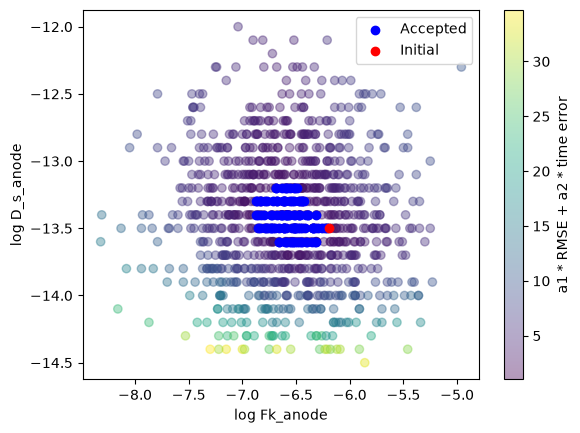

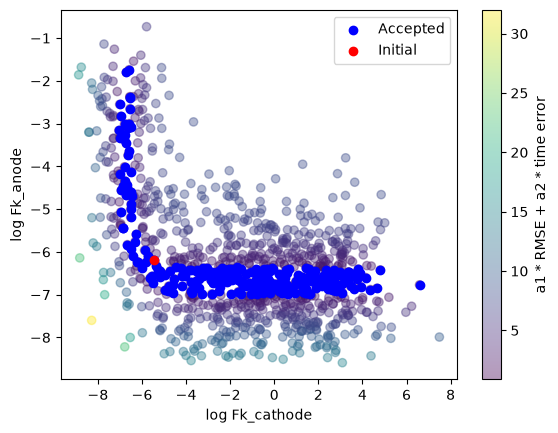

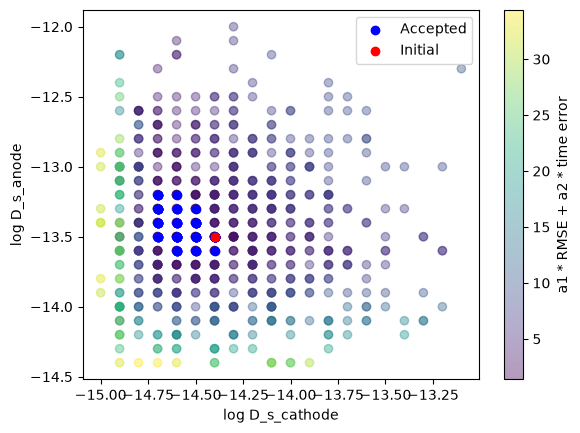

In [2]:
for name0, name1 in [
        ("Fk_cathode", "D_s_cathode"),
        ("Fk_anode", "D_s_anode"),
        ("Fk_cathode", "Fk_anode"),
        ("D_s_cathode", "D_s_anode")
    ]:
    data = np.loadtxt(f"data_metropolis/{name0}-{name1}.data")
    theta0 = data[:, 0]
    theta1 = data[:, 1]
    error = data[:, 2]
    accepted = data[:, 3]

    plt.figure()
    plt.colorbar(plt.scatter(theta0, theta1, c=error, alpha=0.4), label="a1 * RMSE + a2 * time error")

    plt.scatter(theta0[accepted.astype(bool)], theta1[accepted.astype(bool)], c='blue', label="Accepted")
    plt.scatter(theta0[0], theta1[0], c='red', label="Initial")
    plt.xlabel("log " + name0)
    plt.ylabel("log " + name1)
    plt.legend()

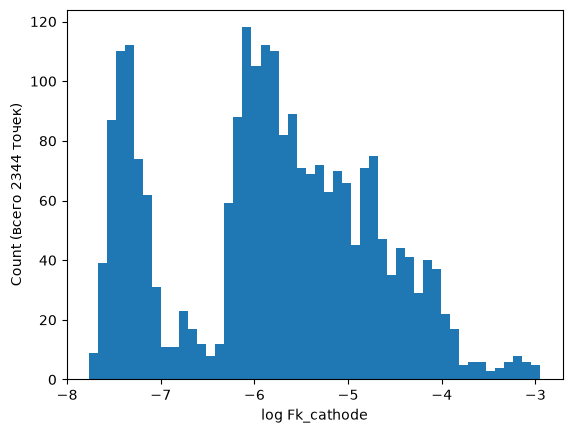

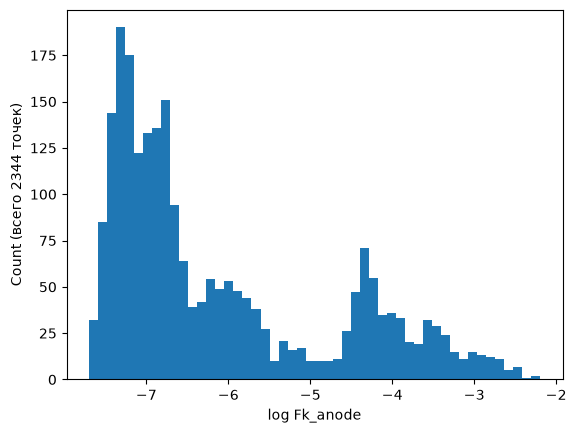

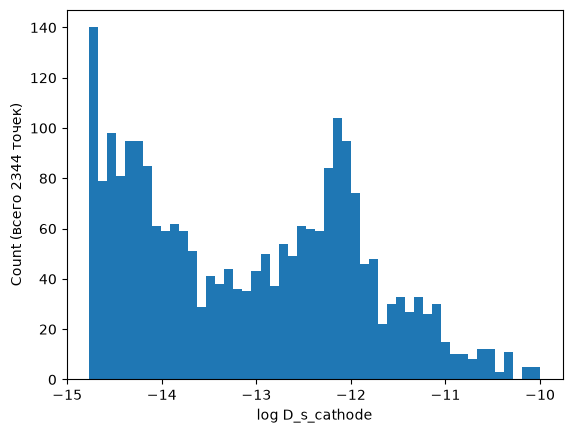

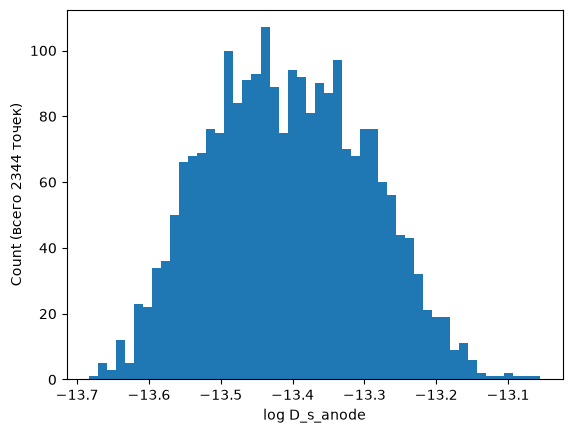

In [15]:
results = {
    "Fk_cathode" : [],
    "Fk_anode" : [],
    "D_s_cathode" : [],
    "D_s_anode" : []
}

for i in range(1, 5):
    data = np.loadtxt(f"data_metropolis/chain{i}.data")
    for t in data[data[:,5].astype(bool), 0]:
        results["Fk_cathode"].append(t)
    for t in data[data[:,5].astype(bool), 1]:
        results["D_s_cathode"].append(t)
    for t in data[data[:,5].astype(bool), 2]:
        results["Fk_anode"].append(t)
    for t in data[data[:,5].astype(bool), 3]:
        results["D_s_anode"].append(t)
        
for name, values in results.items():
    plt.figure()
    plt.hist(values, bins=50)
    plt.xlabel("log " + name)
    plt.ylabel(f"Count (всего {len(values)} точек)")